# LAB 08 — Pretrained Transformers và BERT fine-tuning
Pretrained model **`distilbert-base-uncased`** (6 layer, hidden 768, 12 head, ~66M tham số, pretrained bằng MLM + distillation từ BERT). Classification head tự viết (`pretrained_classification.py`): vector **[CLS]** → Dropout → Linear(768, 2) → softmax.

- Dữ liệu: IMDb, split 60/20/20 stratified seed 2026 giống LAB 04–07 (train 29,746 / val 9,916 / test 9,916).
- Huấn luyện trên **Kaggle GPU**; kết quả mỗi run lưu trong `cache/`, chạy lại notebook ở local sẽ nạp cache (xóa `cache/` để train lại).

In [1]:
import sys, os, time, csv, json, random, math, warnings
sys.path.insert(0, "../lab04")
import numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from transformers import AutoTokenizer
import preprocessing as pp
from pretrained_classification import PretrainedClassifier, train_classifier, predict_proba, extract_cls, MODEL_NAME
warnings.filterwarnings("ignore")
SEED = 2026; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
HW = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU"
print("device:", DEVICE, HW)
RESULTS = []
def log(exp, cfg, metric, val): RESULTS.append((exp, cfg, metric, val))
os.makedirs("cache", exist_ok=True)
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

C:\Users\dinhb\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cpu CPU


In [2]:
data = pp.prepare(pp.load_imdb())
train, val, test = (d.reset_index(drop=True) for d in pp.split(data))
print("train/val/test:", len(train), len(val), len(test))
# training subsets lồng nhau (10% ⊂ 25% ⊂ 50% ⊂ 100%), stratified theo nhãn, seed 2026
perm = {k: np.random.RandomState(SEED).permutation(np.where(train.label.values == k)[0]) for k in (0, 1)}
def subset(frac):
    idx = np.sort(np.concatenate([perm[k][: int(round(len(perm[k]) * frac))] for k in (0, 1)]))
    return train.text.values[idx], train.label.values[idx]
for f in (0.1, 0.25, 0.5, 1.0): print(f"{int(f*100):3d}% → {len(subset(f)[0]):,} review")
EPOCHS, BATCH = 3, 32
CFG = {}
for f in (0.1, 0.25, 0.5, 1.0):
    p = int(f * 100)
    CFG[f"FT_L256_p{p}"] = dict(mode="finetune", L=256, frac=f, lr=2e-5)
    CFG[f"SC_L256_p{p}"] = dict(mode="scratch", L=256, frac=f, lr=1e-4)
for L in (64, 128): CFG[f"FT_L{L}_p100"] = dict(mode="finetune", L=L, frac=1.0, lr=2e-5)
def metrics(y, p):
    q = (p >= .5).astype(int); return dict(accuracy=accuracy_score(y, q), precision=precision_score(y, q), recall=recall_score(y, q), f1=f1_score(y, q))

train/val/test: 29746 9916 9916
 10% → 2,975 review
 25% → 7,436 review
 50% → 14,873 review
100% → 29,746 review


## 13. Core implementation — huấn luyện
- **Fine-tuning** (`FT`): encoder pretrained + head đều train; AdamW lr 2e-5, warmup 10% rồi giảm tuyến tính, batch 32, 3 epoch, fp16 (autocast), gradient clipping 1.0, chọn epoch có validation loss thấp nhất.
- **From scratch** (`SC`): **cùng kiến trúc DistilBERT, cùng tokenizer, cùng max_length / batch / epoch**, nhưng trọng số khởi tạo ngẫu nhiên; lr 1e-4 (model chưa pretrained cần lr lớn hơn mới học được trong 3 epoch).
- **Frozen** (`FZ`): encoder đóng băng, trích vector [CLS] (và thêm mean pooling để so sánh) một lần, chỉ train head Linear(768, 2) (AdamW lr 1e-3, 30 epoch, batch 256, chọn theo validation loss).

In [3]:
def train_run(name):
    path = f"cache/{name}.pt"
    if os.path.exists(path): return torch.load(path, map_location="cpu", weights_only=False)
    c = CFG[name]; Xtr, ytr = subset(c["frac"])
    torch.manual_seed(SEED)
    model = PretrainedClassifier(MODEL_NAME, pretrained=(c["mode"] == "finetune"))
    print(f"== {name}: {len(Xtr):,} review, L={c['L']}, lr={c['lr']}")
    r = train_classifier(model, tok, Xtr, ytr, val.text.values, val.label.values, max_length=c["L"], epochs=EPOCHS, lr=c["lr"], batch_size=BATCH, device=DEVICE, seed=SEED)
    t0 = time.time(); pt = predict_proba(model, tok, test.text.values, c["L"], device=DEVICE); r["test_infer_s"] = time.time() - t0
    r.update(name=name, cfg=c, n_train=len(Xtr), params=model.n_params(), trainable=model.n_params(True), test_probs=pt, test_metrics=metrics(test.label.values, pt), hardware=HW)
    if name in ("FT_L256_p100", "SC_L256_p100"):
        torch.save({k: v.half() for k, v in model.state_dict().items()}, f"cache/{name}_weights_fp16.pt")
    torch.save(r, path); del model; torch.cuda.empty_cache() if DEVICE.type == "cuda" else None
    return r
runs = {n: train_run(n) for n in CFG}

In [4]:
def frozen_features():
    path = "cache/frozen_features.pt"
    if os.path.exists(path): return torch.load(path, map_location="cpu", weights_only=False)
    m = PretrainedClassifier(MODEL_NAME).to(DEVICE); m.freeze_encoder(); m.eval(); out = {}
    @torch.no_grad()
    def feats(texts, L=256, bs=128):
        cls, mean = [], []
        for i in range(0, len(texts), bs):
            e = tok(list(texts[i:i+bs]), padding=True, truncation=True, max_length=L, return_tensors="pt").to(DEVICE)
            with torch.autocast(device_type="cuda", enabled=DEVICE.type == "cuda"):
                H = m.encoder(input_ids=e["input_ids"], attention_mask=e["attention_mask"]).last_hidden_state.float()
            k = e["attention_mask"].unsqueeze(-1).float(); cls.append(H[:, 0].cpu()); mean.append(((H * k).sum(1) / k.sum(1)).cpu())
        return torch.cat(cls), torch.cat(mean)
    t0 = time.time(); out["train"] = feats(train.text.values); out["extract_train_s"] = time.time() - t0
    out["val"] = feats(val.text.values); out["test"] = feats(test.text.values)
    out["frozen_params"] = m.n_params(); out["trainable"] = m.n_params(True)
    torch.save(out, path); return out
FF = frozen_features()
def train_head(Xtr, ytr, Xva, yva, epochs=30, lr=1e-3, bs=256):
    torch.manual_seed(SEED); head = nn.Sequential(nn.Dropout(0.1), nn.Linear(Xtr.shape[1], 2)); opt = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=0.01)
    lf = nn.CrossEntropyLoss(); best = (1e9, None, 0); hist = []; t0 = time.time(); ytr_t = torch.tensor(ytr); yva_t = torch.tensor(yva)
    for ep in range(epochs):
        head.train(); pm = torch.randperm(len(Xtr))
        for i in range(0, len(pm), bs):
            j = pm[i:i+bs]; loss = lf(head(Xtr[j]), ytr_t[j]); opt.zero_grad(); loss.backward(); opt.step()
        head.eval()
        with torch.no_grad(): vl = float(lf(head(Xva), yva_t))
        hist.append(vl)
        if vl < best[0]: best = (vl, {k: v.clone() for k, v in head.state_dict().items()}, ep + 1)
    head.load_state_dict(best[1]); return head, time.time() - t0, best[2], hist
FZ = {}
for pool, k in (("cls", 0), ("mean", 1)):
    for f in (0.1, 0.25, 0.5, 1.0):
        idx = np.sort(np.concatenate([perm[c][: int(round(len(perm[c]) * f))] for c in (0, 1)]))
        head, ht, be, hist = train_head(FF["train"][k][idx], train.label.values[idx], FF["val"][k], val.label.values)
        with torch.no_grad(): pt = torch.softmax(head(FF["test"][k]), -1)[:, 1].numpy()
        FZ[f"FZ_{pool}_p{int(f*100)}"] = dict(test_probs=pt, test_metrics=metrics(test.label.values, pt), head_time=ht, best_epoch=be, val_hist=hist,
                                             extract_s=FF["extract_train_s"] * f, head_state=head.state_dict())
print({k: round(v["test_metrics"]["f1"], 4) for k, v in FZ.items()})

{'FZ_cls_p10': 0.8426, 'FZ_cls_p25': 0.8538, 'FZ_cls_p50': 0.856, 'FZ_cls_p100': 0.8628, 'FZ_mean_p10': 0.8435, 'FZ_mean_p25': 0.8543, 'FZ_mean_p50': 0.8617, 'FZ_mean_p100': 0.867}


## 18. Experiment 5 — Domain shift (chạy trên Kaggle, cần internet để tải dữ liệu)
**Domain A** = IMDb (movie reviews, train và test). **Domain B** (chỉ dùng để test, không train):
- **Amazon** product reviews (`amazon_polarity`, 2,000 mẫu): khác domain (sản phẩm), cùng kiểu review dài;
- **Yelp** restaurant reviews (`yelp_polarity`, 2,000 mẫu): khác domain (nhà hàng, dịch vụ);
- **Tweets** (`tweet_eval` sentiment, bỏ nhãn neutral): khác cả domain lẫn style (ngắn, viết tắt, hashtag, emoji);
- **SST-2** (validation 872 câu): cùng domain phim nhưng là **câu ngắn** thay vì review dài (style shift).

In [5]:
def load_domains():
    path = "cache/domains.pt"
    if os.path.exists(path): return torch.load(path, map_location="cpu", weights_only=False)
    from datasets import load_dataset
    D = {}
    def take(ds, n, fn):
        rows = list(ds.shuffle(seed=SEED, buffer_size=20000).take(n)); return [fn(r) for r in rows]
    try:
        r = take(load_dataset("fancyzhx/amazon_polarity", split="test", streaming=True), 2000, lambda r: (r["title"] + ". " + r["content"], r["label"]))
        D["Amazon"] = ([t for t, _ in r], np.array([l for _, l in r]))
    except Exception as e: print("Amazon lỗi:", e)
    try:
        r = take(load_dataset("fancyzhx/yelp_polarity", split="test", streaming=True), 2000, lambda r: (r["text"], r["label"]))
        D["Yelp"] = ([t for t, _ in r], np.array([l for _, l in r]))
    except Exception as e: print("Yelp lỗi:", e)
    try:
        ds = load_dataset("cardiffnlp/tweet_eval", "sentiment", split="test"); keep = [i for i, l in enumerate(ds["label"]) if l != 1]
        D["Tweets"] = ([ds["text"][i] for i in keep], np.array([1 if ds["label"][i] == 2 else 0 for i in keep]))
    except Exception as e: print("Tweets lỗi:", e)
    try:
        ds = load_dataset("stanfordnlp/sst2", split="validation"); D["SST-2"] = (list(ds["sentence"]), np.array(ds["label"]))
    except Exception as e: print("SST-2 lỗi:", e)
    probs = {}
    ft = PretrainedClassifier(MODEL_NAME); ft.load_state_dict({k: v.float() for k, v in torch.load("cache/FT_L256_p100_weights_fp16.pt", map_location="cpu").items()}); ft.to(DEVICE)
    sc = PretrainedClassifier(MODEL_NAME, pretrained=False); sc.load_state_dict({k: v.float() for k, v in torch.load("cache/SC_L256_p100_weights_fp16.pt", map_location="cpu").items()}); sc.to(DEVICE)
    fz = PretrainedClassifier(MODEL_NAME).to(DEVICE); fz.head[1].load_state_dict({"weight": FZ["FZ_cls_p100"]["head_state"]["1.weight"], "bias": FZ["FZ_cls_p100"]["head_state"]["1.bias"]}); fz.eval()
    for dn, (texts, y) in D.items():
        probs[dn] = {name: predict_proba(m, tok, texts, 256, device=DEVICE) for name, m in (("Fine-tuned", ft), ("Frozen", fz), ("From scratch", sc))}
        print(dn, len(texts), "| positive rate", y.mean().round(3), {k: round(((v >= .5) == y).mean(), 4) for k, v in probs[dn].items()})
    out = dict(data=D, probs=probs); torch.save(out, path); return out
DOM = load_domains()

## 14. Experiment 1 — Pretrained vs from scratch (100% train, max_length 256, 3 epoch)

,Accuracy,Precision,Recall,F1,Training_time_s,Parameters,Trainable,Best_epoch
Model,,,,,,,,
"Transformer from scratch (DistilBERT, khởi tạo ngẫu nhiên)",0.8719,0.9131,0.8232,0.8658,572.9,66364418,66364418,2
Pretrained Transformer + fine-tuning,0.9142,0.9009,0.9315,0.9159,573.3,66364418,66364418,1


Tham khảo LAB 07: Transformer nhỏ tự viết (2 block, d_model 128, vocabulary 20k từ, max_length 256) train from scratch: accuracy 0.8672, F1 0.8660, 2.8M tham số, 134 s.


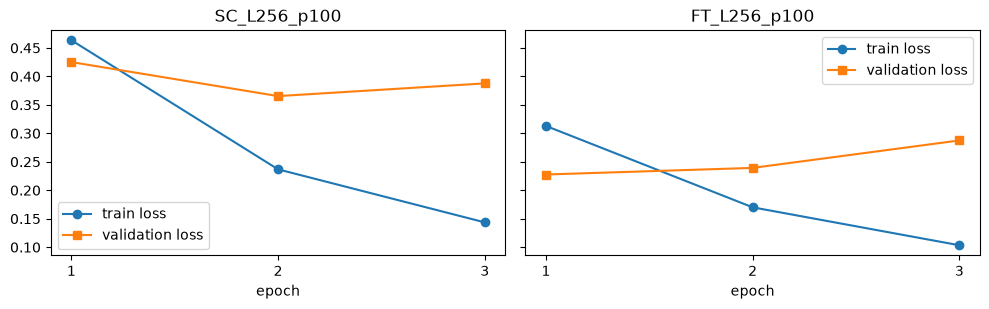

In [6]:
y = test.label.values
def row(label, r, extra=None):
    m = r["test_metrics"]
    return dict(Model=label, Accuracy=round(m["accuracy"], 4), Precision=round(m["precision"], 4), Recall=round(m["recall"], 4), F1=round(m["f1"], 4),
                Training_time_s=round(r["train_time"], 1), Parameters=r["params"], Trainable=r["trainable"], Best_epoch=r["best_epoch"], **(extra or {}))
t1 = pd.DataFrame([row("Transformer from scratch (DistilBERT, khởi tạo ngẫu nhiên)", runs["SC_L256_p100"]), row("Pretrained Transformer + fine-tuning", runs["FT_L256_p100"])]).set_index("Model")
display(t1)
print("Tham khảo LAB 07: Transformer nhỏ tự viết (2 block, d_model 128, vocabulary 20k từ, max_length 256) train from scratch: accuracy 0.8672, F1 0.8660, 2.8M tham số, 134 s.")
for n in ("SC_L256_p100", "FT_L256_p100"):
    for k, v in runs[n]["test_metrics"].items(): log("exp1_pretrained_vs_scratch", n, k, round(v, 4))
    log("exp1_pretrained_vs_scratch", n, "train_time_s", round(runs[n]["train_time"], 1)); log("exp1_pretrained_vs_scratch", n, "params", runs[n]["params"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, n in zip(axes, ("SC_L256_p100", "FT_L256_p100")):
    h = runs[n]["hist"]; e = range(1, len(h["train_loss"]) + 1)
    ax.plot(e, h["train_loss"], "o-", label="train loss"); ax.plot(e, h["val_loss"], "s-", label="validation loss"); ax.set_title(n); ax.set_xlabel("epoch"); ax.set_xticks(list(e)); ax.legend()
plt.tight_layout(); plt.show()

**Nhận xét Experiment 1** (cùng kiến trúc DistilBERT 66.4M tham số, cùng tokenizer, max_length 256, 3 epoch, cùng GPU T4):
- Pretrained + fine-tuning: accuracy **0.914**, F1 **0.916**; from scratch: 0.872 / 0.866 (ngang Transformer nhỏ của LAB 07: 0.867 / 0.866). Pretraining tăng ~4.2 điểm accuracy.
- **Representation:** model pretrained bắt đầu từ embedding + attention đã học ngôn ngữ trên ~3.3 tỷ từ (BookCorpus + Wikipedia, kế thừa BERT); [CLS] sau fine-tuning tóm tắt sentiment dựa trên ngữ cảnh. Model from scratch phải học nghĩa từ, cú pháp và task cùng lúc từ 29,746 review; nó lệch hẳn về negative (precision 0.913, recall chỉ 0.823).
- **Training data:** fine-tuned đạt val accuracy 0.908 ngay sau epoch 1 (best epoch = 1, sau đó overfit); from scratch cần 2 epoch và vẫn thấp hơn.
- **Chi phí tính toán:** mỗi epoch như nhau (cùng kiến trúc, ~191 s trên T4), nhưng model pretrained cần ít epoch hơn để tốt; phần chi phí lớn nhất (pretraining) đã được người khác trả trước. So với LAB 07 (2.8M tham số, 134 s), DistilBERT lớn gấp ~23 lần và chậm hơn ~4 lần.
- **So với prediction:** đúng (dự đoán +3–5 điểm, thực tế +4.2 so với scratch cùng kiến trúc, +4.7 so với LAB 07).

## 15. Experiment 2 — Feature extraction (frozen) vs fine-tuning (100% train, max_length 256)

In [7]:
ft = runs["FT_L256_p100"]; rows = []
for name, lab_ in (("FZ_cls_p100", "Frozen — [CLS]"), ("FZ_mean_p100", "Frozen — mean pooling")):
    r = FZ[name]; m = r["test_metrics"]
    rows.append({"Mode": lab_, "Encoder trainable?": "No", "Accuracy": round(m["accuracy"], 4), "F1": round(m["f1"], 4),
                 "Training time (s)": f"{FF['extract_train_s']:.0f} (trích feature) + {r['head_time']:.1f} (head)", "Trainable params": 768 * 2 + 2})
m = ft["test_metrics"]
rows.append({"Mode": "Fine-tuning", "Encoder trainable?": "Yes", "Accuracy": round(m["accuracy"], 4), "F1": round(m["f1"], 4), "Training time (s)": f"{ft['train_time']:.0f}", "Trainable params": ft["trainable"]})
t2 = pd.DataFrame(rows).set_index("Mode"); display(t2)
for name in ("FZ_cls_p100", "FZ_mean_p100"):
    for k, v in FZ[name]["test_metrics"].items(): log("exp2_frozen_vs_finetune", name, k, round(v, 4))
log("exp2_frozen_vs_finetune", "FZ", "extract_train_s", round(FF["extract_train_s"], 1))

,Encoder trainable?,Accuracy,F1,Training time (s),Trainable params
Mode,,,,,
Frozen — [CLS],No,0.8627,0.8628,66 (trích feature) + 25.5 (head),1538
Frozen — mean pooling,No,0.8647,0.8670,66 (trích feature) + 25.4 (head),1538
Fine-tuning,Yes,0.9142,0.9159,573,66364418


**Nhận xét Experiment 2:**
- Frozen [CLS]: accuracy 0.863, F1 0.863; frozen mean pooling: 0.865 / 0.867; fine-tuning: 0.914 / 0.916. Frozen kém ~5 điểm, khớp prediction (chọn C).
- Frozen chỉ train **1,538** tham số (head) so với 66.4M; thời gian 66 s trích feature (một lần forward) + 25 s train head, so với 573 s fine-tuning.
- **Vì sao frozen vẫn phân loại được?** Representation pretrained đã mã hóa nghĩa từ và ngữ cảnh: các review khen/chê nằm ở các vùng khác nhau của không gian 768 chiều, nên một ranh giới tuyến tính đã tách được 86%.
- **Vì sao fine-tuning tốt hơn?** [CLS] của DistilBERT không được huấn luyện để tóm tắt sentiment (MLM không dùng [CLS]); fine-tuning cho phép mọi layer điều chỉnh để dồn thông tin sentiment vào [CLS], ví dụ học cách xử lý "not", "but" trong ngữ cảnh. Mean pooling nhỉnh hơn [CLS] ở chế độ frozen vì [CLS] chưa được dạy tóm tắt câu.

## 16. Experiment 3 — Amount of training data (validation/test cố định)

,n_train,Fine-tuned Acc,Fine-tuned F1,Frozen F1,Scratch Acc,Scratch F1,FT time (s),Scratch time (s)
Training data,,,,,,,,
10%,2975,0.8801,0.8826,0.8426,0.8258,0.8272,54.0,58.0
25%,7436,0.9059,0.9059,0.8538,0.8255,0.8404,144.0,144.0
50%,14873,0.9067,0.9085,0.8560,0.8658,0.8665,287.0,286.0
100%,29746,0.9142,0.9159,0.8628,0.8719,0.8658,573.0,573.0


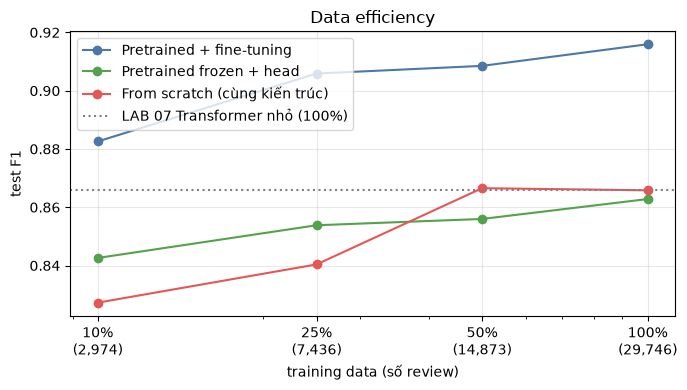

In [8]:
rows = []
for f in (0.1, 0.25, 0.5, 1.0):
    p = int(f * 100); a, b, c = runs[f"FT_L256_p{p}"], FZ[f"FZ_cls_p{p}"], runs[f"SC_L256_p{p}"]
    rows.append({"Training data": f"{p}%", "n_train": a["n_train"], "Fine-tuned Acc": round(a["test_metrics"]["accuracy"], 4), "Fine-tuned F1": round(a["test_metrics"]["f1"], 4),
                 "Frozen F1": round(b["test_metrics"]["f1"], 4), "Scratch Acc": round(c["test_metrics"]["accuracy"], 4), "Scratch F1": round(c["test_metrics"]["f1"], 4),
                 "FT time (s)": round(a["train_time"], 0), "Scratch time (s)": round(c["train_time"], 0)})
    for n, r in ((f"FT_L256_p{p}", a), (f"FZ_cls_p{p}", b), (f"SC_L256_p{p}", c)):
        log("exp3_data_efficiency", n, "accuracy|f1", f"{r['test_metrics']['accuracy']:.4f}|{r['test_metrics']['f1']:.4f}")
t3 = pd.DataFrame(rows).set_index("Training data"); display(t3)
x = [10, 25, 50, 100]
fig, ax = plt.subplots(figsize=(7, 4))
for key, lab_, c in (("FT_L256_p", "Pretrained + fine-tuning", "#4c78a8"), ("FZ_cls_p", "Pretrained frozen + head", "#54a24b"), ("SC_L256_p", "From scratch (cùng kiến trúc)", "#e45756")):
    src = FZ if key.startswith("FZ") else runs
    ax.plot(x, [src[f"{key}{p}"]["test_metrics"]["f1"] for p in x], "o-", color=c, label=lab_)
ax.axhline(0.8660, color="gray", ls=":", label="LAB 07 Transformer nhỏ (100%)")
ax.set_xscale("log"); ax.set_xticks(x); ax.set_xticklabels([f"{p}%\n({int(29746*p/100):,})" for p in x]); ax.set_xlabel("training data (số review)"); ax.set_ylabel("test F1")
ax.set_title("Data efficiency"); ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.savefig("data_efficiency.png", dpi=130); plt.show()

**Nhận xét Experiment 3 (dựa trên toàn bộ đường cong, xem `data_efficiency.png`):**
- Ở **mọi** mức dữ liệu, fine-tuned cao nhất: F1 0.883 / 0.906 / 0.909 / 0.916 (10 / 25 / 50 / 100%).
- **Fine-tuned với 10% dữ liệu (2,975 review, F1 0.883) đã vượt from scratch với 100% (29,746 review, F1 0.866)** và vượt Transformer LAB 07 (0.866): dùng ít hơn 10 lần dữ liệu có nhãn mà tốt hơn.
- Từ 100% xuống 10%: from scratch giảm 3.9 điểm F1, fine-tuned giảm 3.3, frozen giảm 2.0. From scratch giảm nhiều hơn nhưng chênh không lớn; đường của from scratch còn không đơn điệu (50% ≈ 100%), cho thấy kết quả from scratch kém ổn định.
- Fine-tuned tăng nhanh từ 10% → 25% (+2.3) rồi gần bão hòa (+1.0 từ 25% → 100%); pretraining giúp model dùng dữ liệu downstream hiệu quả hơn: cùng lượng dữ liệu nhãn thì luôn tốt hơn, và đạt một mức chất lượng với ít dữ liệu hơn nhiều.

## 17. Experiment 4 — Maximum sequence length (fine-tuning, 100% train)

In [9]:
rows = []
for L, n in ((64, "FT_L64_p100"), (128, "FT_L128_p100"), (256, "FT_L256_p100")):
    r = runs[n]; m = r["test_metrics"]
    rows.append({"Max length": L, "Accuracy": round(m["accuracy"], 4), "F1": round(m["f1"], 4), "Training time (s)": round(r["train_time"], 0),
                 "Peak GPU memory (MB)": (round(r["peak_mem_mb"]) if r["peak_mem_mb"] == r["peak_mem_mb"] else np.nan), "T² (attention / head)": L * L})
    log("exp4_seq_length", f"L={L}", "accuracy|f1|time_s|peak_MB", f"{m['accuracy']:.4f}|{m['f1']:.4f}|{r['train_time']:.0f}|{r['peak_mem_mb']:.0f}")
t4 = pd.DataFrame(rows).set_index("Max length"); display(t4)

,Accuracy,F1,Training time (s),Peak GPU memory (MB),T² (attention / head)
Max length,,,,,
64,0.8363,0.8371,221.0,1645,4096
128,0.8807,0.8843,325.0,2065,16384
256,0.9142,0.9159,573.0,2932,65536


**Nhận xét Experiment 4:**
- 64 → 128 → 256 token: F1 0.837 → 0.884 → 0.916; thời gian 221 → 325 → 573 s; peak GPU 1.6 → 2.1 → 2.9 GB.
- Với IMDb, tăng max_length **giúp nhiều** vì review dài (trung vị 226 token DistilBERT; 64 token chỉ giữ 22% token). Nhưng chi phí tăng nhanh: T² ×16 từ 64 → 256 (attention), thời gian ×2.6; phần không phải attention (FFN, embedding) tăng tuyến tính nên tổng chưa tăng đúng T².
- **Tăng sequence length luôn tốt hơn?** Không nhất thiết: lợi ích phụ thuộc thông tin có nằm sau vị trí cắt không (với câu ngắn như SST-2/tweet thì 64 là đủ), còn chi phí luôn tăng; DistilBERT cũng không vượt quá 512 vì position embedding chỉ có 512 vị trí.

## 18. Experiment 5 — Kết quả domain shift

In [10]:
rows = []
for name, key in (("Fine-tuned", "FT_L256_p100"), ("Frozen", "FZ_cls_p100"), ("From scratch", "SC_L256_p100")):
    src = FZ if key.startswith("FZ") else runs
    r = {"Model": name, "IMDb (in-domain)": round(src[key]["test_metrics"]["accuracy"], 4)}
    for dn, (texts, yy) in DOM["data"].items():
        r[dn] = round(((DOM["probs"][dn][name] >= .5) == yy).mean(), 4)
    rows.append(r)
t5 = pd.DataFrame(rows).set_index("Model"); display(t5.rename_axis("accuracy"))
info = pd.DataFrame({dn: {"n": len(t), "positive rate": round(yy.mean(), 3), "trung vị số từ": int(np.median([len(s.split()) for s in t]))} for dn, (t, yy) in DOM["data"].items()})
info["IMDb (test)"] = {"n": len(test), "positive rate": round(y.mean(), 3), "trung vị số từ": int(np.median([len(s.split()) for s in test.text]))}; display(info)
for _, r in t5.reset_index().iterrows():
    for c in t5.columns: log("exp5_domain_shift", f"{r['Model']}|{c}", "accuracy", r[c])
pf = DOM["probs"]
for dn, (texts, yy) in DOM["data"].items():
    p = pf[dn]["Fine-tuned"]; print(f"{dn:7s} fine-tuned: F1 {f1_score(yy, (p>=.5).astype(int)):.4f} | dự đoán positive {np.mean(p>=.5):.3f} (thật {yy.mean():.3f})")

,IMDb (in-domain),Amazon,Yelp,Tweets,SST-2
accuracy,,,,,
Fine-tuned,0.9142,0.9305,0.899,0.8164,0.8635
Frozen,0.8627,0.8575,0.860,0.7496,0.8050
From scratch,0.8719,0.8125,0.780,0.6973,0.7144


,Amazon,Yelp,Tweets,SST-2,IMDb (test)
n,2000.000,2000.000,6347.000,872.000,9916.000
positive rate,0.506,0.484,0.374,0.509,0.502
trung vị số từ,72.000,100.000,16.000,19.000,172.000


Amazon  fine-tuned: F1 0.9330 | dự đoán positive 0.531 (thật 0.506)
Yelp    fine-tuned: F1 0.8938 | dự đoán positive 0.467 (thật 0.484)
Tweets  fine-tuned: F1 0.7735 | dự đoán positive 0.436 (thật 0.374)
SST-2   fine-tuned: F1 0.8688 | dự đoán positive 0.531 (thật 0.509)


**Nhận xét Experiment 5 (domain shift):**
- Fine-tuned trên IMDb vẫn mạnh trên review dạng khác: **Amazon 0.931** (còn cao hơn IMDb 0.914, vì review sản phẩm ngắn và rõ sentiment), **Yelp 0.899**; giảm trên **SST-2 0.864** (câu phim ngắn, khác style) và giảm mạnh nhất trên **Tweets 0.816** (ngắn, viết tắt, hashtag, mỉa mai; model dự đoán positive 43.6% trong khi thật là 37.4%).
- From scratch giảm mạnh hơn nhiều: IMDb 0.872 → Tweets 0.697, SST-2 0.714. Frozen ở giữa. Pretraining giúp **chống domain shift** (từ "battery", "waiter" có nghĩa sẵn từ pretraining), model scratch chỉ biết từ ngữ của review phim.
- **Pretrained có "hiểu mọi domain" không?** Không. Accuracy giảm 10 điểm trên tweet; hiệu năng phụ thuộc mức khác biệt về style/độ dài/từ ngữ so với dữ liệu fine-tune. Lưu ý một phần chênh lệch cũng có thể do nhãn của dataset khác cách định nghĩa (tweet_eval gán nhãn theo người annotate tweet).

## 19. Application — Evaluation đầy đủ của model fine-tuned (test IMDb)

Accuracy 0.9142 | Precision 0.9009 | Recall 0.9315 | F1 0.9159
Fine-tuned (FT_L256)   TN=4429 FP=510 FN=341 TP=4636
Frozen [CLS]           TN=4275 FP=664 FN=697 TP=4280
From scratch           TN=4549 FP=390 FN=880 TP=4097


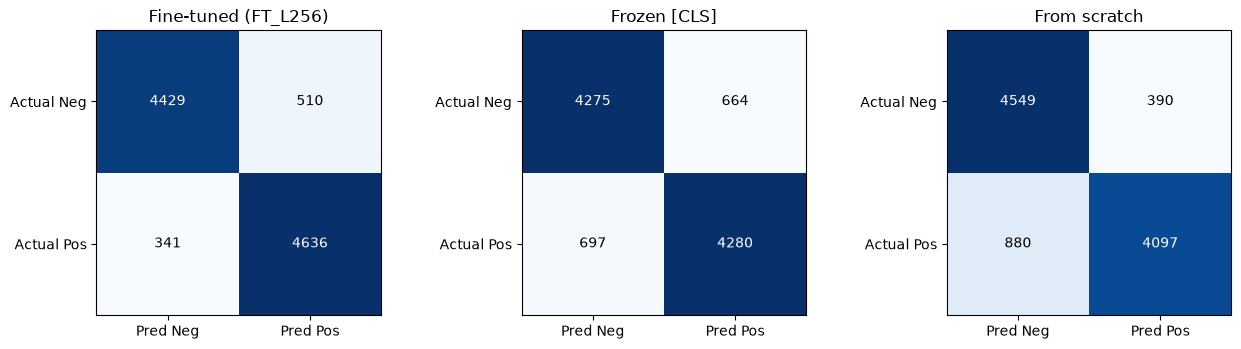

In [11]:
pb = runs["FT_L256_p100"]["test_probs"]; pred = (pb >= .5).astype(int); m = runs["FT_L256_p100"]["test_metrics"]
print("Accuracy {accuracy:.4f} | Precision {precision:.4f} | Recall {recall:.4f} | F1 {f1:.4f}".format(**m))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (lab_, p) in zip(axes, (("Fine-tuned (FT_L256)", pb), ("Frozen [CLS]", FZ["FZ_cls_p100"]["test_probs"]), ("From scratch", runs["SC_L256_p100"]["test_probs"]))):
    cm = confusion_matrix(y, (p >= .5).astype(int)); ax.imshow(cm, cmap="Blues"); ax.set_title(lab_)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xticklabels(["Pred Neg", "Pred Pos"]); ax.set_yticklabels(["Actual Neg", "Actual Pos"])
    for i in range(2):
        for j in range(2): ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
    tn, fp, fn, tp = cm.ravel(); log("confusion", lab_, "TN_FP_FN_TP", f"{tn},{fp},{fn},{tp}"); print(f"{lab_:22s} TN={tn} FP={fp} FN={fn} TP={tp}")
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=130); plt.show()

In [12]:
# Dùng model fine-tuned (trọng số fp16 tải từ Kaggle) để dự đoán câu mới trên CPU
clf = PretrainedClassifier(MODEL_NAME); clf.load_state_dict({k: v.float() for k, v in torch.load("cache/FT_L256_p100_weights_fp16.pt", map_location="cpu").items()}); clf.eval()
cases = [("ngắn", "I really enjoyed this movie."), ("negation", "I did not enjoy this movie at all."), ("double negation", "It's not that the movie isn't good."),
         ("contrast", "I thought this movie would be bad, but it was actually excellent."), ("contrast ngược", "The cast is brilliant, but the film itself is a boring mess."),
         ("sarcasm", "Oh great, another two hours of my life I will never get back."), ("ambiguous", "The movie was okay, not great but not terrible either."),
         ("domain: sản phẩm", "The battery died after two days and support never answered."), ("domain: tweet", "omg this film is lit 🔥🔥 cant wait 4 the sequel lol")]
p_app = predict_proba(clf, tok, [s for _, s in cases], 256)
display(pd.DataFrame({"Loại": [c for c, _ in cases], "Câu": [s for _, s in cases], "Prediction": ["Positive" if p >= .5 else "Negative" for p in p_app],
                      "P(positive)": p_app.round(3), "Confidence": np.maximum(p_app, 1 - p_app).round(3)}).set_index("Loại"))
for (c, s), p in zip(cases, p_app): log("application", c, "P_positive", round(float(p), 4))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1751.31it/s]


[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,Câu,Prediction,P(positive),Confidence
Loại,,,,
ngắn,I really enjoyed this movie.,Positive,0.991,0.991
negation,I did not enjoy this movie at all.,Negative,0.035,0.965
double negation,It's not that the movie isn't good.,Negative,0.074,0.926
contrast,"I thought this movie would be bad, but it was ...",Positive,0.952,0.952
contrast ngược,"The cast is brilliant, but the film itself is ...",Negative,0.021,0.979
sarcasm,"Oh great, another two hours of my life I will ...",Positive,0.547,0.547
ambiguous,"The movie was okay, not great but not terrible...",Negative,0.284,0.716
domain: sản phẩm,The battery died after two days and support ne...,Negative,0.245,0.755
domain: tweet,omg this film is lit 🔥🔥 cant wait 4 the sequel...,Negative,0.461,0.539


**Nhận xét Application:** đúng với câu ngắn (0.991), negation "I did not enjoy..." (0.035), contrast cả hai chiều (0.952 và 0.021: model fine-tuned xử lý "but" tốt hơn LAB 07, nơi câu contrast bị sai), câu sản phẩm (Negative 0.245) và câu ambiguous (Negative 0.284, confidence chỉ 0.72). **Double negation** "It's not that the movie isn't good" (ý: phim không tệ) bị đoán Negative 0.074 với confidence cao: hai từ phủ định được hiểu như tín hiệu tiêu cực. Sai rõ: **sarcasm** "Oh great, another two hours of my life I will never get back" → Positive 0.547 (bị "great" kéo) và **tweet** "omg this film is lit 🔥🔥..." → Negative 0.461 (slang "lit", emoji không có trong dữ liệu phim; tokenizer biến 🔥🔥 thành [UNK], "omg" thành om ##g). Cả hai lỗi đều có confidence thấp (0.55), không giống các câu đúng (≥ 0.93).

## 21. Confidence analysis (model fine-tuned, test IMDb)
confidence = max(softmax(logits)) = max(p, 1 − p). Chia: **High** ≥ 0.95, **Medium** 0.75–0.95, **Low** < 0.75.

,n,accuracy,% of test,số lỗi
bin,,,,
Low (<0.75),1063,0.5992,10.7,426
Medium (0.75–0.95),2262,0.8594,22.8,318
High (≥0.95),6591,0.9838,66.5,107


ECE (expected calibration error) = 0.0125


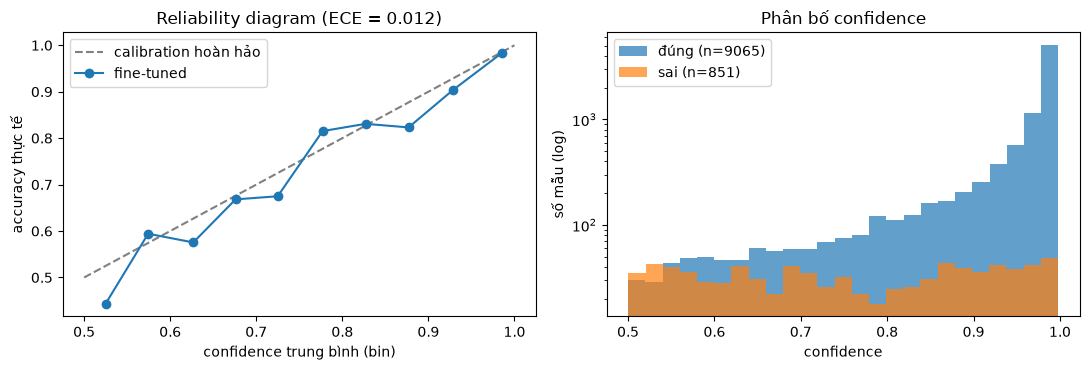

Amazon : confidence trung bình 0.915 | accuracy 0.930 | tỉ lệ High-confidence mà sai 0.009
Yelp   : confidence trung bình 0.868 | accuracy 0.899 | tỉ lệ High-confidence mà sai 0.003
Tweets : confidence trung bình 0.722 | accuracy 0.816 | tỉ lệ High-confidence mà sai 0.001
SST-2  : confidence trung bình 0.863 | accuracy 0.864 | tỉ lệ High-confidence mà sai 0.011


In [13]:
conf = np.maximum(pb, 1 - pb); correct = pred == y
bins = pd.cut(conf, [0.5, 0.75, 0.95, 1.0001], labels=["Low (<0.75)", "Medium (0.75–0.95)", "High (≥0.95)"], include_lowest=True)
tc = pd.DataFrame({"bin": bins, "correct": correct}).groupby("bin", observed=False).agg(n=("correct", "size"), accuracy=("correct", "mean"))
tc["% of test"] = (tc.n / len(y) * 100).round(1); tc["số lỗi"] = (tc.n * (1 - tc.accuracy.fillna(1))).round().astype(int); tc["accuracy"] = tc.accuracy.round(4); display(tc)
for b, r in tc.iterrows(): log("confidence", str(b), "n|accuracy", f"{r.n}|{r.accuracy}")
edges = np.linspace(0.5, 1.0, 11); mids, accs, cnt = [], [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    k = (conf >= lo) & (conf < hi if hi < 1 else conf <= hi)
    if k.sum(): mids.append(conf[k].mean()); accs.append(correct[k].mean()); cnt.append(k.sum())
ece = sum(c / len(y) * abs(a - m_) for m_, a, c in zip(mids, accs, cnt)); print(f"ECE (expected calibration error) = {ece:.4f}")
log("confidence", "FT_L256_p100", "ECE", round(float(ece), 4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot([0.5, 1], [0.5, 1], "--", color="gray", label="calibration hoàn hảo"); ax[0].plot(mids, accs, "o-", label="fine-tuned")
ax[0].set_xlabel("confidence trung bình (bin)"); ax[0].set_ylabel("accuracy thực tế"); ax[0].set_title(f"Reliability diagram (ECE = {ece:.3f})"); ax[0].legend()
ax[1].hist(conf[correct], bins=25, alpha=.7, label=f"đúng (n={correct.sum()})"); ax[1].hist(conf[~correct], bins=25, alpha=.7, label=f"sai (n={(~correct).sum()})")
ax[1].set_yscale("log"); ax[1].set_xlabel("confidence"); ax[1].set_ylabel("số mẫu (log)"); ax[1].set_title("Phân bố confidence"); ax[1].legend()
plt.tight_layout(); plt.savefig("confidence_analysis.png", dpi=130); plt.show()
for dn, (texts, yy) in DOM["data"].items():
    p = DOM["probs"][dn]["Fine-tuned"]; c_ = np.maximum(p, 1 - p); ok_ = (p >= .5) == yy
    print(f"{dn:7s}: confidence trung bình {c_.mean():.3f} | accuracy {ok_.mean():.3f} | tỉ lệ High-confidence mà sai {np.mean((c_ >= .95) & ~ok_):.3f}")

**Nhận xét Confidence analysis:**
- 66.5% test có confidence ≥ 0.95 với accuracy 0.984; Medium 0.859; Low 0.599 (gần đoán mò). Model **khá calibrated** (ECE 0.0125): confidence trung bình gần với accuracy thực tế.
- Nhưng **confidence ≠ correctness**: vẫn có **107 lỗi với confidence ≥ 0.95** (13% tổng số 851 lỗi), có mẫu sai với confidence 0.998. Confidence cao chỉ là xác suất model tự gán, không đảm bảo đúng, đặc biệt với nhãn nhiễu hoặc sarcasm.
- Trên Tweets confidence trung bình giảm (0.72) cùng với accuracy (0.82): ở đây confidence phản ánh đúng việc model không chắc; nhưng SST-2 có confidence 0.863 ≈ accuracy 0.864 nên không phải lúc nào cũng thấy được domain shift qua confidence.

## 20. Error analysis (model fine-tuned) — 3 false positive, 3 false negative, 2 sai với confidence rất cao
Chọn ngẫu nhiên (seed 2026) trong các review ≤ 200 từ để đọc được trọn vẹn; 2 mẫu "rất tự tin nhưng sai" lấy từ các lỗi có confidence cao nhất.

In [14]:
T_ = test.text.values; nw = np.array([len(t.split()) for t in T_]); rng = np.random.RandomState(SEED)
fp_i = rng.choice(np.where((pred == 1) & (y == 0) & (nw <= 200))[0], 3, replace=False)
fn_i = rng.choice(np.where((pred == 0) & (y == 1) & (nw <= 200))[0], 3, replace=False)
wrong = np.where(pred != y)[0]; hc_i = wrong[np.argsort(-conf[wrong])][:2]
lab = {0: "negative", 1: "positive"}; ntok = lambda t: len(tok(t)["input_ids"])
for title, ids in (("FALSE POSITIVE", fp_i), ("FALSE NEGATIVE", fn_i), ("SAI VỚI CONFIDENCE CAO NHẤT", hc_i)):
    print(f"===== {title} =====")
    for i in ids:
        print(f"[idx {i}] true={lab[y[i]]} pred={lab[pred[i]]} confidence={conf[i]:.3f} | {nw[i]} từ, {ntok(T_[i])} token | scratch p={runs['SC_L256_p100']['test_probs'][i]:.2f}\n  {T_[i]}\n")
        log("error_analysis", f"{title}|idx={i}", "true|pred|conf", f"{y[i]}|{pred[i]}|{conf[i]:.3f}")

===== FALSE POSITIVE =====
[idx 5743] true=negative pred=positive confidence=0.635 | 158 từ, 186 token | scratch p=0.03
  Saw this movie when it first came out in the 1970's and hated, hated, hated it! Easily the most booooring movie I have ever seen in my life. Don't know where Leigh got his inspiration but this is one of those movies where you want to shake the characters to get them to open their mouths and communicate. The title says it all because there are no saving moments in this movie, just long, long silences with people unable to articulate what they are (presumably) feeling. If you want to watch something that will drive you to drink then this is the one for you. If you have nothing better to do for two hours then stick a fork in a toaster: the experience will be infinitely more pleasurable than anything you will get from this! Yes, Leigh came up with a lot of really worthwhile stuff much later in his career but give this one a miss.

[idx 1901] true=negative pred=positive 

In [15]:
# Kiểm chứng các giả thuyết lỗi trên toàn test set
ntoks = np.array([ntok(t) for t in T_]); err = pred != y
negw = {"not", "no", "never", "nothing", "don't", "didn't", "isn't", "wasn't", "doesn't"}
neg = np.array([bool(set(pp.tokenize(t)) & negw) for t in T_]); cont = np.array([bool(set(pp.tokenize(t)) & {"but", "however", "although", "though"}) for t in T_])
tab = pd.DataFrame({"tỉ lệ lỗi": [err[ntoks <= 256].mean(), err[ntoks > 256].mean(), err[neg].mean(), err[~neg].mean(), err[cont].mean(), err[~cont].mean()],
                    "n": [(ntoks <= 256).sum(), (ntoks > 256).sum(), neg.sum(), (~neg).sum(), cont.sum(), (~cont).sum()]},
                   index=["≤ 256 token", "> 256 token (bị truncate)", "có từ phủ định", "không có phủ định", "có từ tương phản", "không có tương phản"]).round(4)
display(tab)
for idx_, r in tab.iterrows(): log("error_analysis", f"err_rate|{idx_}", "rate", r["tỉ lệ lỗi"])
# Review dài bị sai: đọc phần CUỐI (256 token cuối) có sửa được không?
long_wrong = np.where(err & (ntoks > 256))[0]
tail = [tok.convert_tokens_to_string(tok.tokenize(T_[i])[-254:]) for i in long_wrong]
p_tail = predict_proba(clf, tok, tail, 256); fixed = ((p_tail >= .5) == y[long_wrong]).mean()
print(f"{len(long_wrong)} review dài bị sai khi đọc 256 token đầu → đọc 256 token cuối thì đúng {fixed:.1%}")
log("error_analysis", "FT long wrong reviews", "fixed_by_reading_tail", round(float(fixed), 4))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (814 > 512). Running this sequence through the model will result in indexing errors


,tỉ lệ lỗi,n
≤ 256 token,0.0659,5904
> 256 token (bị truncate),0.1152,4012
có từ phủ định,0.0887,8524
không có phủ định,0.0682,1392
có từ tương phản,0.0940,7747
không có tương phản,0.0567,2169


462 review dài bị sai khi đọc 256 token đầu → đọc 256 token cuối thì đúng 65.4%


**Bảng phân loại lỗi** (model fine-tuned; nguyên nhân là hypothesis, có kiểm chứng ở dưới):

| # | Text (rút gọn) | True | Pred | Confidence | Error type | Hypothesis |
|---|---|---|---|--:|---|---|
| FP1 | "hated, hated, hated it! ... most booooring movie ... stick a fork in a toaster ... Leigh came up with a lot of really worthwhile stuff much later" | neg | pos | 0.635 | rare word / tokenization + context | "booooring" bị cắt thành boo ##oor ##ing nên mất tín hiệu "boring"; câu khen sự nghiệp về sau của đạo diễn ở cuối kéo về positive. |
| FP2 | "This film may be great, but it is a complete ripoff of ... Comfort and Joy ... sweetest films ... I can recommend almost anything by forsythe" | neg | pos | 0.569 | context (khen phim **khác**) | Lời khen dành cho phim gốc (Comfort and Joy, Forsythe), model không phân biệt đối tượng được khen. |
| FP3 | "loved the book ... The actors are to be commended ... smarmy, overwrought script ... insulted" | neg | pos | 0.504 | ambiguous sentiment | Khen sách và diễn viên, chê phim; gần ngưỡng 0.5. |
| FN1 | "Convoluted, infuriating and implausible ... completely ridiculous ... offers something that defies description" | pos | neg | 0.927 | ambiguous / label ambiguity | Phần lớn từ ngữ chê; positive chỉ thể hiện gián tiếp ("Parker Posey is really the only actress who could..."). |
| FN2 | "I just don't understand why this movie is getting beat-up ... mindless, it isn't polished ... wasted on some ... The jokes work on more then one level" | pos | neg | 0.988 | negation + context (bênh vực phim) | Review phản bác người khác nên lặp lại các từ chê ("mindless", "panned", "disappointed"); model đếm từ chê mà không hiểu đó là ý kiến bị phản bác. |
| FN3 | "mess of a movie ... mediocre ... slow ... great story of Australian history ... 6/10" | pos | neg | 0.917 | ambiguous / label ambiguity | Review 6/10 lẫn lộn, nhiều từ chê; nhãn positive theo điểm số chứ không theo từ ngữ. |
| HC1 | "This sleek, sexy movie is a must-see ... masterpiece ... the trainables ... sexual experience" | neg | pos | **0.998** | sarcasm | Khen quá mức một phim (giáo dục giới tính) một cách mỉa mai; mọi từ đều là từ khen. |
| HC2 | "Great movie - especially the music - Etta James - 'At Last'..." | neg | pos | **0.996** | label ambiguity / noise | Nội dung hoàn toàn khen; nhãn negative có vẻ sai. Model đúng theo text. |

**Kiểm chứng giả thuyết:** review > 256 token lỗi 11.5% so với 6.6% (gần gấp đôi) → **truncation** là nguồn lỗi lớn; với 462 review dài bị sai, chỉ cần đọc **256 token cuối** thay vì đầu là đúng **65.4%** (kết luận review thường ở cuối). Review có từ phủ định lỗi 8.9% so với 6.8%; có từ tương phản 9.4% so với 5.7%. Cả hai lỗi confidence cao nhất (sarcasm, nhãn nhiễu) đều **cũng sai ở model from scratch** (p = 0.99, 0.98): đây là giới hạn của dữ liệu/nhãn, không riêng của pretraining.

## 23. Reproducibility

In [16]:
r = runs["FT_L256_p100"]
repro = {"Model": f"{MODEL_NAME} (HuggingFace) + head Dropout(0.1) → Linear(768, 2) trên [CLS]", "Tokenizer": f"{type(tok).__name__} (WordPiece, uncased, vocabulary {len(tok):,})",
         "Dataset": "IMDb 50k (Kaggle lakshmi25npathi), bỏ HTML, bỏ 418 review trùng → 49,578", "Train split": f"{len(train):,} (60%, stratified, seed 2026)",
         "Validation split": f"{len(val):,} (20%)", "Test split": f"{len(test):,} (20%)", "Max sequence length": "256 (Exp 4: 64 / 128 / 256)", "Batch size": BATCH,
         "Learning rate": "2e-5 (fine-tuning), 1e-4 (from scratch), 1e-3 (frozen head); warmup 10% + linear decay", "Epochs": f"{EPOCHS} (chọn epoch theo validation loss)",
         "Optimizer": "AdamW (weight decay 0.01), gradient clipping 1.0, fp16 autocast", "Random seed": SEED, "Hardware": r["hardware"] + " (Kaggle)",
         "Training time": f"{r['train_time']:.0f} s cho {EPOCHS} epoch fine-tuning ({np.mean(r['hist']['epoch_s']):.0f} s/epoch); suy luận test {r['test_infer_s']:.0f} s"}
display(pd.DataFrame({"": repro}))

,
Model,distilbert-base-uncased (HuggingFace) + head D...
Tokenizer,"BertTokenizer (WordPiece, uncased, vocabulary ..."
Dataset,"IMDb 50k (Kaggle lakshmi25npathi), bỏ HTML, bỏ..."
Train split,"29,746 (60%, stratified, seed 2026)"
Validation split,"9,916 (20%)"
Test split,"9,916 (20%)"
Max sequence length,256 (Exp 4: 64 / 128 / 256)
Batch size,32
Learning rate,"2e-5 (fine-tuning), 1e-4 (from scratch), 1e-3 ..."
Epochs,3 (chọn epoch theo validation loss)


## Lưu kết quả

In [17]:
with open("results.csv", "w", newline="", encoding="utf8") as f:
    wr = csv.writer(f); wr.writerow(["experiment", "config", "metric", "value"]); wr.writerows(RESULTS)
print(len(RESULTS), "rows → results.csv")

82 rows → results.csv
